# 1. A sampling campaign, round by round
> The loop that the experiments simulate: units, ground truth, prior, samples, state, strategy and score

Temporary series explaining the scoring work on the `scoring-experiments` branch:

0. A primer on Bayesian statistics, for trufl
1. A sampling campaign, round by round (this notebook)
2. The MCDM layer
3. What a good campaign means
4. The sawtooth in the restriction rule
5. From `bayes` to `voi`
6. Spatial correlation and where to place samples

The code lives in `07_scoring.ipynb`, the comparisons in `_scoring_experiments.ipynb`, the results in `scoring-plan.md` and the proposed design in `scoring-design.md`. The first cell runs the code cells of `07_scoring.ipynb` to load its definitions. It takes a few seconds.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from fastcore.nbio import read_nb
warnings.filterwarnings('ignore')
for c in read_nb('07_scoring.ipynb').cells:
    if c.cell_type == 'code': get_ipython().run_cell(c.source, silent=True).raise_error()
from functools import partial

## Ground truth and units

A simulation needs a map of the truth that the campaign pretends not to know: here the simulated contamination raster `ground-truth-01`. Decisions are made per unit, such as a municipality; `gridder` stands in for real boundaries with a 10 by 10 grid. `Campaign` reads each unit's raster cells once:

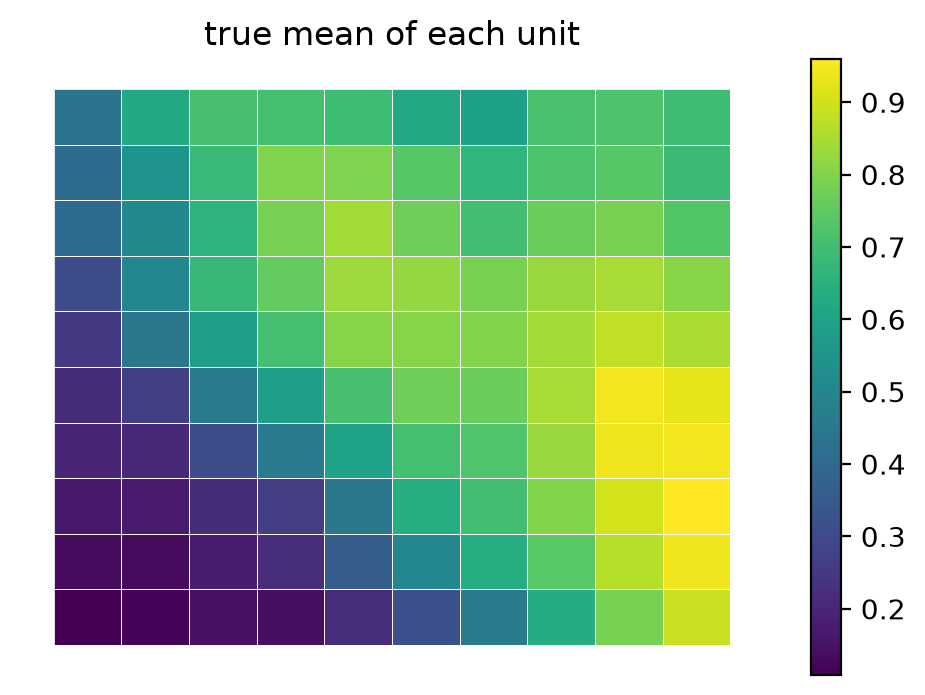

In [ ]:
camp = Campaign(fname_raster, gdf_grid, score=partial(decisions, level=0.8))
true_mean = camp.truth.map(np.mean)
ax = gdf_grid.assign(true_mean=true_mean).plot(column='true_mean', legend=True, figsize=(6, 4))
gdf_grid.boundary.plot(ax=ax, color='white', lw=0.3)
ax.set(title='true mean of each unit'); ax.axis('off');

## Prior

Before any sample, decision makers usually have a prior, such as an airborne survey: coarser and noisier than the truth. `degrade` makes one by averaging the truth over blocks of cells and adding noise:

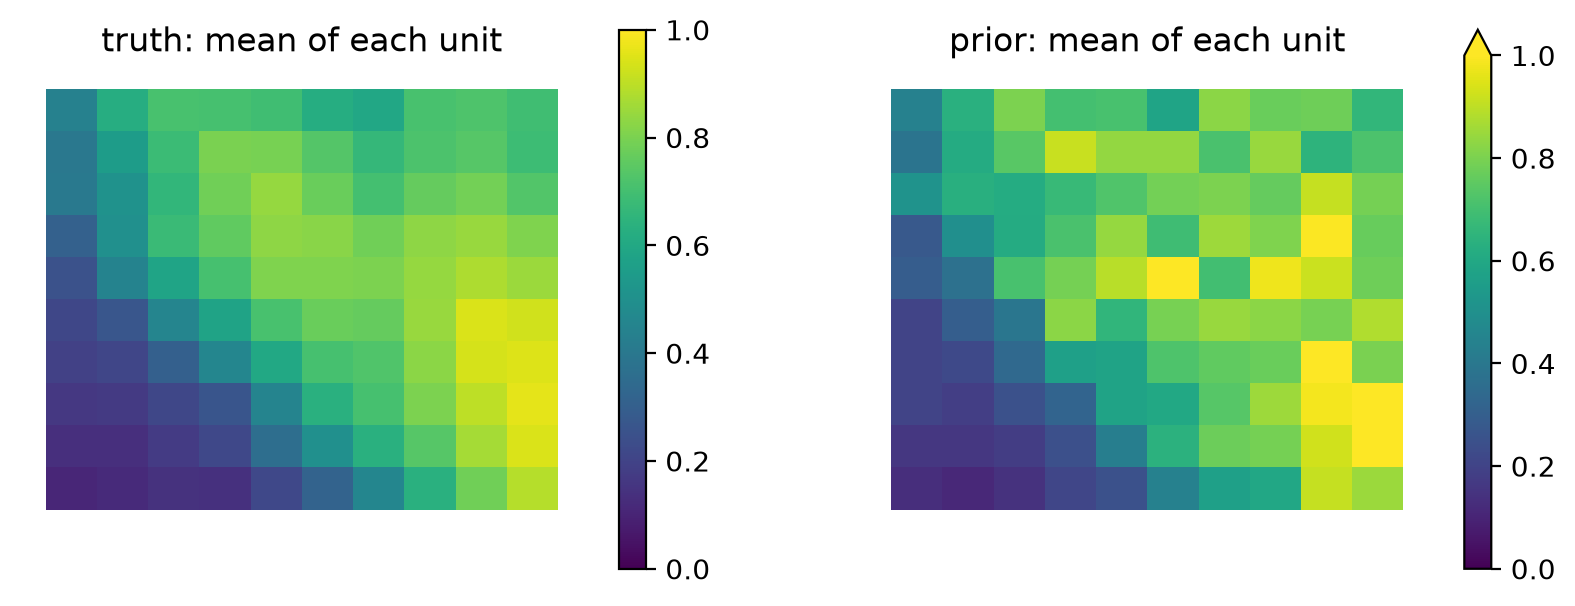

In [ ]:
fprior = degrade(fname_raster, os.path.join(tempfile.mkdtemp(), 'prior.tif'), factor=10, noise=0.3, seed=0)
prior_mean = unit_values(fprior, gdf_grid).map(np.mean)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, v) in zip(axs, {'truth': true_mean, 'prior': prior_mean}.items()):
    gdf_grid.assign(v=v).plot(column='v', ax=ax, vmin=0, vmax=1, legend=True)
    ax.set(title=f'{name}: mean of each unit'); ax.axis('off')

## One round

A strategy turns what is known so far into a number of samples for each unit. `Campaign.step` places the samples uniformly at random inside each unit and reads the raster under each one, as a field team would measure them. Here, round 1 with equal allocation of 150 samples:

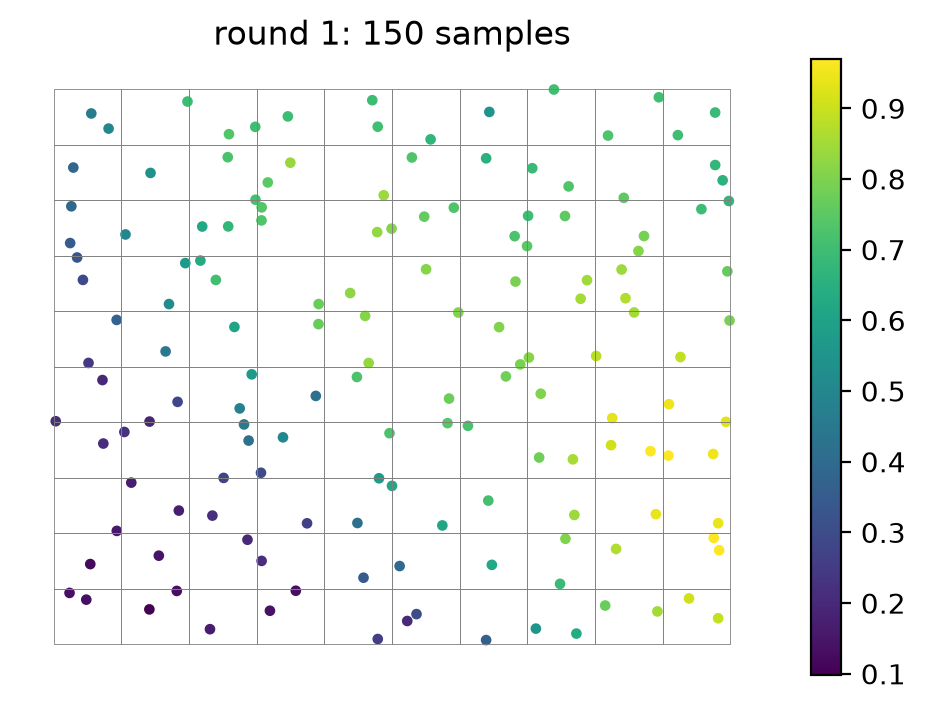

In [ ]:
camp.reset(seed=0)
n1 = equal(0)(camp.samples, gdf_grid, 150, camp.rng)
table1 = camp.step(n1)
ax = gdf_grid.boundary.plot(color='grey', lw=0.3, figsize=(6, 4))
camp.samples.plot(column='value', ax=ax, markersize=8, legend=True)
ax.set(title='round 1: 150 samples'); ax.axis('off');

## State

The how-to strategy describes each unit by state variables computed from the samples so far: maximum, minimum, standard deviation, count, Moran's I and the prior. Notebook 2 shows how MCDM turns such a table into a ranking:

In [ ]:
state = State(camp.samples, gdf_grid, cbs=[MaxCB(), MinCB(), StdCB(), CountCB(), MoranICB(k=5), PriorCB(fprior)])()
state.head()

,Max,Min,Standard Deviation,Count,Moran.I,Prior
loc_id,,,,,,
0,0.135663,0.133169,0.001247,2,NaN,0.129544
1,0.121966,0.121966,0.000000,1,NaN,0.157836
2,0.155971,0.155971,0.000000,1,NaN,0.201861
3,0.208576,0.208576,0.000000,1,NaN,0.201313
4,0.212340,0.197603,0.007369,2,NaN,0.201783


Moran's I is missing everywhere: it needs more than 5 samples in a unit. A unit with one sample has a standard deviation of 0. Both are open questions in `scoring-plan.md`.

## Strategies decide where the samples go

Different strategies split the same round differently. Equal allocation ignores what is known. The how-to strategy ranks the units by MCDM and splits the budget by rank. `voi` targets the units whose restriction decision is most likely to be wrong (notebook 5). Round 2, after the samples above:

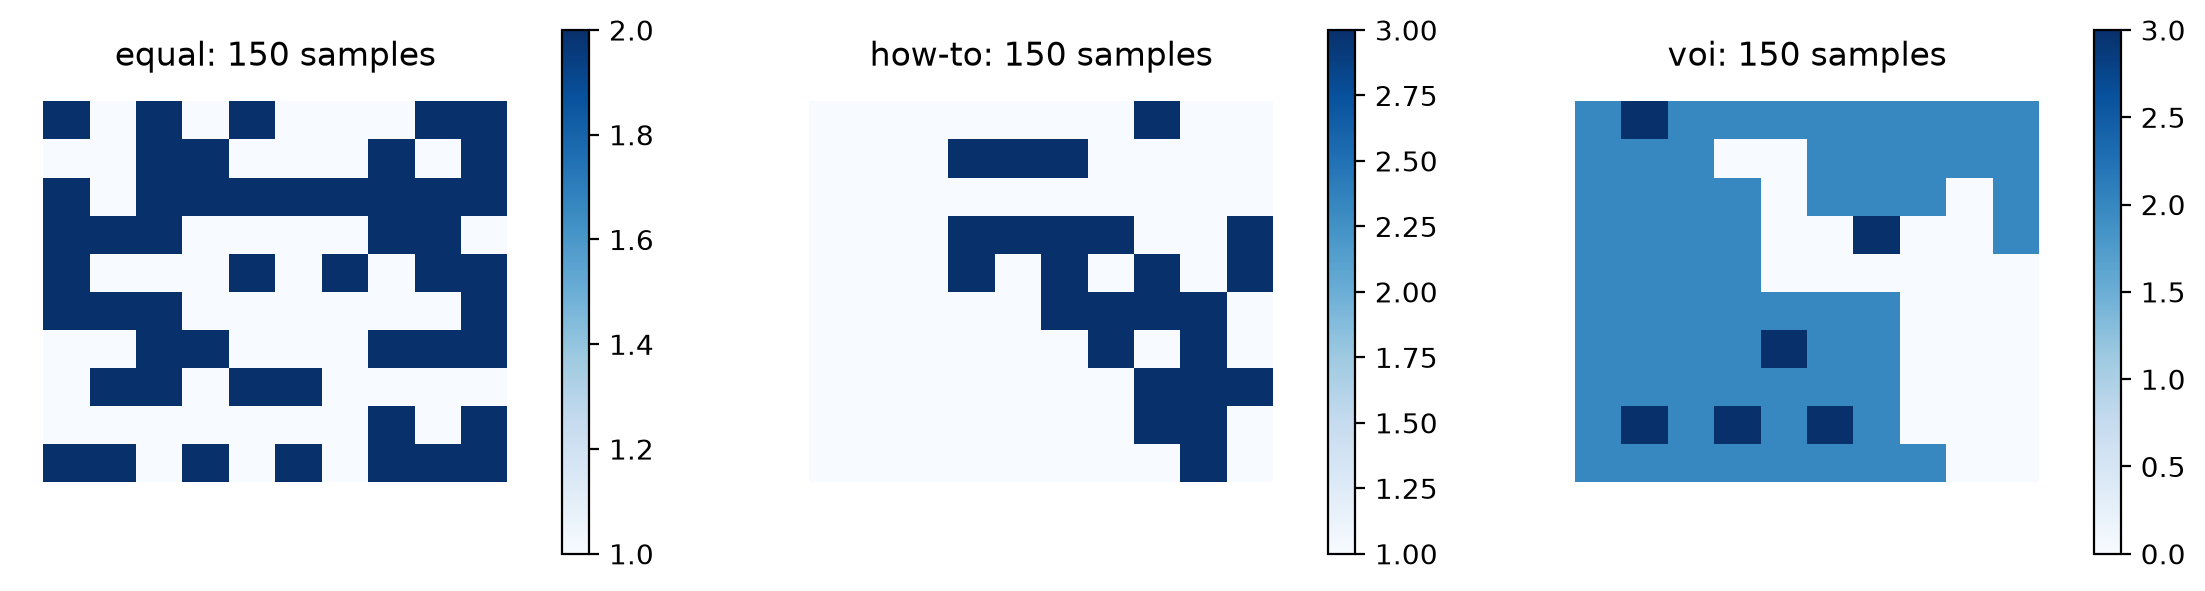

In [ ]:
strategies = {'equal': equal(0), 'how-to': mcdm(fprior, min=1), 'voi': voi(0.8, 0.1, min_total=1)}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, s) in zip(axs, strategies.items()):
    n = s(camp.samples, gdf_grid, 150, np.random.default_rng(0))
    gdf_grid.assign(n=n).plot(column='n', ax=ax, legend=True, cmap='Blues')
    ax.set(title=f'{name}: {n.sum()} samples'); ax.axis('off')

## A whole campaign and its score

`run` repeats this for several rounds and returns the score after each one. Here the score is the decision score of notebook 3: each unit's restriction decision from its samples, against the decision the truth calls for, with a permissible level of 0.8 and 10% accepted:

In [ ]:
res = {name: summarise_decisions(run(camp, s, budgets=[150] * 6, seed=0)) for name, s in strategies.items()}
pd.concat(res, names=['strategy']).wrong.unstack()

round,1,2,3,4,5,6
strategy,,,,,,
equal,7,5,5,5,5,4
how-to,5,4,4,3,3,5
voi,7,6,5,3,3,3


One seed is one possible campaign. The experiments repeat each campaign over 20 seeds and several ground truths before comparing strategies. `compare` does that.